#### Relevance annotation

Independent VLM-as-a-Judge and manual ratings for all 19 images.

In [1]:
# Loading the Top 10 Output
import torch

phase2_output = torch.load(
    "../outputs/phase_2_output.pt",
    map_location="cpu",
    weights_only=True
)

print(phase2_output.keys())

dict_keys(['context_embedding', 'top_images', 'top_image_embeddings'])


In [2]:
print("Context embedding:", phase2_output["context_embedding"].shape)

print("Top images:", len(phase2_output["top_images"]))

print("Top image embeddings:", phase2_output["top_image_embeddings"].shape)

Context embedding: torch.Size([1, 512])
Top images: 10
Top image embeddings: torch.Size([10, 512])


In [3]:
# What do we need for evaluation?
# Our goal is to compare:
# Original Unsplash retrieval order vs FashionCLIP reranking.
# For that, we need all 19 candidate images, not just the Top-10.
# We have the original unsplash data stored in the JSON

In [4]:
# Same as Day3
import json
from pathlib import Path

api_dir = Path("../data/image_api_calls")

api_files = sorted(
    [path for path in api_dir.glob("unsplash_search_*.json") if path.stem.rsplit("_", 1)[-1].isdigit()],
    key=lambda path: int(path.stem.rsplit("_", 1)[-1])
)

print("API response files:", len(api_files))

API response files: 9


In [5]:
# Extract MetaData -- Same as Day3
all_retrieved_images = []

for file_path in api_files:

    with open(file_path, "r", encoding="utf-8") as file:
        data = json.load(file)

    query_number = int(file_path.stem.rsplit("_", 1)[-1])

    for photo in data["results"]:

        image_record = {
            "image_id": photo["id"],
            "image_url": photo["urls"]["small"],
            "source_url": photo["links"]["html"],
            "description": (
                photo.get("description")
                or photo.get("alt_description")
            ),
            "photographer": photo["user"]["name"],
            "photographer_url": photo["user"]["links"]["html"],
            "query_number": query_number
        }

        all_retrieved_images.append(image_record)

print("Total retrieved records:", len(all_retrieved_images))

Total retrieved records: 43


In [6]:
# Deduplicate
unique_images = {}

for image in all_retrieved_images:

    image_id = image["image_id"]

    if image_id not in unique_images:
        unique_images[image_id] = image

retrieved_images = list(unique_images.values())

print("Unique images:", len(retrieved_images))

Unique images: 19


In [7]:
# Prepare the evaluation records

evaluation_records = []

for i, image in enumerate(retrieved_images):

    record = image.copy()

    record["original_rank"] = i + 1
    record["fashionclip_rank"] = None
    record["similarity_score"] = None

    evaluation_records.append(record)

In [8]:
top_images = phase2_output["top_images"]

for image in top_images:

    image_id = image["image_id"]

    for record in evaluation_records:

        if record["image_id"] == image_id:

            record["fashionclip_rank"] = image["rank"]
            record["similarity_score"] = image["similarity_score"]

            break

In [9]:
print("Evaluation records:", len(evaluation_records))

print(
    "Records with FashionCLIP ranks:",
    sum(
        record["fashionclip_rank"] is not None
        for record in evaluation_records
    )
)

print(
    "Records without FashionCLIP ranks:",
    sum(
        record["fashionclip_rank"] is None
        for record in evaluation_records
    )
)

Evaluation records: 19
Records with FashionCLIP ranks: 10
Records without FashionCLIP ranks: 9


In [10]:
# Create a manual labeling interface
# Lets display each image with its identifier and description
# We'll use the image URLs directly and include photographer attribution.

from IPython.display import display, HTML
from html import escape

for i, record in enumerate(evaluation_records, start=1):

    image_url = escape(record["image_url"], quote=True)
    image_id = escape(record["image_id"])
    description = escape(record["description"] or "No description")
    photographer = escape(record["photographer"])
    photographer_url = escape(record["photographer_url"], quote=True)
    source_url = escape(record["source_url"], quote=True)

    display(HTML(f"""
        <div style="margin-bottom:25px;">

            <h4>Image {i} | ID: {image_id}</h4>

            <img src="{image_url}"
                 style="width:300px;
                        height:400px;
                        object-fit:contain;">

            <p>Description: {description}</p>

            <p>
                Photo by
                <a href="{photographer_url}">{photographer}</a>
                on
                <a href="{source_url}">Unsplash</a>
            </p>

        </div>
    """))

In [61]:
# Assigning Relevance Labels Manually

# 2 - Highly relevant - Winter coat, trousers, boots, suitable for sightseeing or dinner, broadly minimalist
# 1 - Partially relevant - Some appropriate clothing, but missing important winter or activity requirements
# 0 - Irrelevant - Beachwear, summer-only outfits, or unrelated images

manual_labels = [
    2, 0, 2, 1, 1,
    2, 0, 1, 1, 2,
    2, 1, 2, 2, 1,
    0, 1, 2, 2
]


In [62]:
# valid manual label check

assert len(manual_labels) == len(evaluation_records)
assert all(label in (0, 1, 2) for label in manual_labels)

In [63]:
# Attach the manual labels to evaluation records
for record, label in zip(evaluation_records, manual_labels):
    record["manual_relevance"] = label

In [64]:
# Verify annotations

from collections import Counter

label_counts = Counter(manual_labels)

print("Highly relevant:", label_counts[2])
print("Partially relevant:", label_counts[1])
print("Irrelevant:", label_counts[0])
print("Total labeled:", len(manual_labels))

Highly relevant: 9
Partially relevant: 7
Irrelevant: 3
Total labeled: 19


In [65]:
# VLM as a Judge to assign relevance labels (0,1,2)
# Using "gemini-2.5-flash"
# Restart Kernel after installing google-genai

In [20]:
# %pip install google-genai

In [19]:
# importing the package
from google import genai

In [22]:
# Load your gemini key
import os
from pathlib import Path
from dotenv import load_dotenv

load_dotenv(Path("../.env"))

GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")

if not GEMINI_API_KEY:
    raise ValueError("Gemini API key not found.")

print("Gemini API key loaded successfully.")

Gemini API key loaded successfully.


In [ ]:
# Initialize Gemini Client for communicating with Gemini
client = genai.Client(api_key=GEMINI_API_KEY)

MODEL_NAME = "gemini-2.5-flash"

print("Gemini client initialized.")

Gemini client initialized.


In [24]:
# Judge Prompt

judge_prompt = """
You are an independent fashion relevance evaluator.

Evaluate the provided fashion image against the following
travel and clothing requirements.

TRAVEL CONTEXT:
Destination: Seoul
Season: Winter

Weather Clothing Requirements:
- Outerwear: winter coat, puffer jacket
- Top: sweater, knitwear
- Bottom: long trousers
- Footwear: closed shoes, boots
- Properties: warm, insulated, layerable, weather-resistant

Activity Style Requirements:
- Sightseeing: casual, comfortable
- Dinner: smart casual, polished

User Style: minimalist

RELEVANCE LABELS:

2 - Highly Relevant:
The image shows an outfit broadly suitable for winter,
matches at least one requested activity, and generally
aligns with the user's preferred style.

1 - Partially Relevant:
The outfit satisfies some requirements but has notable
weather, clothing, or activity-style mismatches.

0 - Irrelevant:
The image is unrelated to fashion or clearly unsuitable
for the travel context.

EVALUATION RULES:
1. Evaluate visible clothing and outfit characteristics.
2. Do not assume hidden properties such as insulation
   or waterproofing from appearance alone.
3. Do not use FashionCLIP similarity scores or rankings.
4. Evaluate each image independently.
5. Return only a JSON object containing:
   relevance_label, reason, confidence.

Confidence must be low, medium, or high.
"""

In [27]:
judge_prompt = """
You are an independent fashion relevance evaluator.

Evaluate the provided image against the following
travel and clothing requirements.

TRAVEL CONTEXT:
Destination: Seoul
Season: Winter

Weather Clothing Requirements:
- Outerwear: winter coat, puffer jacket
- Top: sweater, knitwear
- Bottom: long trousers
- Footwear: closed shoes, boots
- Properties: warm, insulated, layerable, weather-resistant

Activity Style Requirements:
- Sightseeing: casual, comfortable
- Dinner: smart casual, polished

User Style: minimalist

RELEVANCE LABELS:

2 - Highly Relevant:
Winter-appropriate clothing, suitable for sightseeing
or dinner, broadly matching minimalist style.

1 - Partially Relevant:
Some suitable garments or styling, but important
weather or activity requirements are missing.

0 - Irrelevant:
Clearly inappropriate for winter or unrelated
to fashion inspiration.

EVALUATION RULES:

1. Evaluate the visible clothing and outfit characteristics.

2. An outfit does NOT need to satisfy both sightseeing
   and dinner requirements. Matching at least one
   activity is sufficient for a highly relevant rating,
   provided weather and style requirements are
   broadly satisfied.

3. Do not require every listed garment to be present.
   The clothing requirements include alternatives,
   such as winter coat OR puffer jacket.

4. Do not assume hidden clothing properties such as
   insulation or waterproofing based on appearance alone.

5. Do not use FashionCLIP similarity scores, rankings,
   search-query metadata, or human relevance labels.

6. Evaluate the image independently using only the
   provided travel context and visible image content.

7. Return only a JSON object containing:
   - relevance_label: integer (0, 1, or 2)
   - reason: brief explanation based on visible evidence
   - confidence: low, medium, or high
"""

In [45]:
judge_prompt = """
You are an independent fashion relevance evaluator.

Evaluate the provided image against the following
travel and clothing requirements.

TRAVEL CONTEXT:
Destination: Seoul
Season: Winter

Weather Clothing Requirements:
- Outerwear: winter coat, puffer jacket
- Top: sweater, knitwear
- Bottom: long trousers
- Footwear: closed shoes, boots
- Properties: warm, insulated, layerable, weather-resistant

Activity Style Requirements:
- Sightseeing: casual, comfortable
- Dinner: smart casual, polished

User Style: minimalist


RELEVANCE LABELS:

2 - Highly Relevant:
Winter-appropriate clothing, suitable for sightseeing
or dinner, broadly matching minimalist style.

1 - Partially Relevant:
Some appropriate clothing or styling, but missing
important winter or activity requirements.

0 - Irrelevant:
Beachwear, summer-only outfits, clearly inappropriate
winter clothing, or images unrelated to fashion inspiration.


EXAMPLE CLASSIFICATIONS:

Example 1:
Visible clothing: Winter coat, sweater, trousers, boots.
Relevance Label: 2
Reason: Winter-appropriate outfit with suitable layering,
appropriate for sightseeing or dinner.

Example 2:
Visible clothing: Minimalist puffer jacket outfit.
Relevance Label: 2
Reason: Winter-appropriate outerwear that broadly matches
the user's minimalist style preference.

Example 3:
Visible clothing: Casual trousers and shirt,
without winter layering.
Relevance Label: 1
Reason: Some appropriate casual clothing, but insufficient
winter suitability.

Example 4:
Visible clothing: Beachwear.
Relevance Label: 0
Reason: Clearly unsuitable for Seoul winter.

Example 5:
Visible clothing: Winter knitwear with long trousers.
Relevance Label: 2
Reason: Suitable winter clothing that broadly matches
the user's requirements.


EVALUATION RULES:

1. Evaluate visible clothing and outfit characteristics.

2. An outfit does NOT need to satisfy both sightseeing
   and dinner requirements. Matching at least one
   activity is sufficient for a highly relevant rating,
   provided weather and style requirements are
   broadly satisfied.

3. Do not require every listed garment to be present.
   Clothing requirements include alternatives,
   such as winter coat OR puffer jacket.

4. Do not assume hidden clothing properties such as
   insulation or waterproofing based on appearance alone.

5. Do not use FashionCLIP similarity scores, rankings,
   search-query metadata, or human relevance labels.

6. Evaluate the image independently using only the
   provided travel context and visible image content.

7. Apply the relevance labels consistently using
   the definitions and examples provided above.

8. Return only a JSON object containing:
   - relevance_label: integer (0, 1, or 2)
   - reason: brief explanation based on visible evidence
   - confidence: low, medium, or high
"""

In [46]:
# Testing Gemini on 1 image

from PIL import Image
from google.genai import types
import json

image = Image.open("../test_images/image1.jpg").convert("RGB")

In [47]:
response = client.models.generate_content(
    model="gemini-2.5-flash",
    contents=[
        judge_prompt,
        image
    ],
    config=types.GenerateContentConfig(
        response_mime_type="application/json",
        response_schema={
            "type": "OBJECT",
            "properties": {
                "relevance_label": {
                    "type": "INTEGER"
                },
                "reason": {
                    "type": "STRING"
                },
                "confidence": {
                    "type": "STRING",
                    "enum": ["low", "medium", "high"]
                }
            },
            "required": [
                "relevance_label",
                "reason",
                "confidence"
            ]
        }
    )
)

result = json.loads(response.text)

print(result)

ClientError: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-2.5-flash\nPlease retry in 16h9m49.159849785s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTier', 'quotaDimensions': {'location': 'global', 'model': 'gemini-2.5-fla

In [30]:
assert result["relevance_label"] in (0, 1, 2)
assert result["confidence"] in ("low", "medium", "high")

print("Relevance Label:", result["relevance_label"])
print("Reason:", result["reason"])
print("Confidence:", result["confidence"])

Relevance Label: 2
Reason: The outfit features a winter coat, sweater, long trousers, and boots, which are appropriate for winter weather. The casual styling with a beanie and jeans is suitable for sightseeing and aligns with a minimalist aesthetic.
Confidence: high


In [32]:
import requests
from PIL import Image
from io import BytesIO

def load_image_from_url(image_url):
    response = requests.get(image_url, timeout=20)
    response.raise_for_status()

    image = Image.open(BytesIO(response.content)).convert("RGB")

    return image

In [33]:
images_for_judging = []

for record in evaluation_records:
    image = load_image_from_url(record["image_url"])
    images_for_judging.append(image)

print("Images loaded:", len(images_for_judging))

Images loaded: 19


In [34]:
# Evaluating for 19 images

import json
from google.genai import types

vlm_results = []

for record, image in zip(evaluation_records, images_for_judging):

    try:
        response = client.models.generate_content(
            model="gemini-2.5-flash",
            contents=[judge_prompt, image],
            config=types.GenerateContentConfig(
                response_mime_type="application/json",
                response_schema={
                    "type": "OBJECT",
                    "properties": {
                        "relevance_label": {"type": "INTEGER"},
                        "reason": {"type": "STRING"},
                        "confidence": {
                            "type": "STRING",
                            "enum": ["low", "medium", "high"]
                        }
                    },
                    "required": [
                        "relevance_label",
                        "reason",
                        "confidence"
                    ]
                }
            )
        )

        result = json.loads(response.text)

        assert result["relevance_label"] in (0, 1, 2)
        assert result["confidence"] in ("low", "medium", "high")

        result["image_id"] = record["image_id"]
        vlm_results.append(result)

        print(
            f"Image {len(vlm_results)} | "
            f"Label: {result['relevance_label']}"
        )

    except Exception as e:
        print(f"Failed: {record['image_id']} | {e}")

Image 1 | Label: 1
Image 2 | Label: 1
Image 3 | Label: 2
Image 4 | Label: 1
Image 5 | Label: 0
Image 6 | Label: 1
Image 7 | Label: 1
Image 8 | Label: 0
Image 9 | Label: 0
Image 10 | Label: 2
Image 11 | Label: 1
Image 12 | Label: 0
Image 13 | Label: 1
Image 14 | Label: 2
Image 15 | Label: 0
Image 16 | Label: 0
Image 17 | Label: 1
Image 18 | Label: 2
Image 19 | Label: 2


In [54]:
# Adding to evaluation records by image_id
vlm_by_id = {
    result["image_id"]: result
    for result in vlm_results
}

for record in evaluation_records:
    result = vlm_by_id.get(record["image_id"])

    record["vlm_relevance"] = (
        result["relevance_label"] if result else None
    )
    record["vlm_reason"] = (
        result["reason"] if result else None
    )
    record["vlm_confidence"] = (
        result["confidence"] if result else None
    )

In [55]:
print("Total images:", len(evaluation_records))

print(
    "VLM labels available:",
    sum(
        record["vlm_relevance"] is not None
        for record in evaluation_records
    )
)

Total images: 19
VLM labels available: 19


In [56]:
# Calculate percentage agreement
'''
Agreement=Number of matching labels/Total images
'''

'\nAgreement=Number of matching labels/Total images\n'

In [67]:
import numpy as np

manual = np.array([
    record["manual_relevance"]
    for record in evaluation_records
])

vlm = np.array([
    record["vlm_relevance"]
    for record in evaluation_records
])

agreement = np.mean(manual == vlm)

print(f"Human-VLM Agreement: {agreement:.2%}")

Human-VLM Agreement: 42.11%


In [68]:
from collections import Counter

print("Manual label distribution:", Counter(manual))
print("Gemini label distribution:", Counter(vlm))

Manual label distribution: Counter({np.int64(2): 9, np.int64(1): 7, np.int64(0): 3})
Gemini label distribution: Counter({np.int64(1): 8, np.int64(0): 6, np.int64(2): 5})


In [69]:
# %pip install pandas

In [71]:
import pandas as pd

comparison_df = pd.DataFrame([
    {
        "Image ID": record["image_id"],
        "Manual": record["manual_relevance"],
        "Gemini": record["vlm_relevance"],
        "Agreement": (
            record["manual_relevance"]
            == record["vlm_relevance"]
        ),
        "Gemini Reason": record["vlm_reason"]
    }
    for record in evaluation_records
])

display(comparison_df)

,Image ID,Manual,Gemini,Agreement,Gemini Reason
0,rXANayuznKI,2,1,False,The outfit features a sweater and long trouser...
1,cdlrjH_8g48,0,1,False,The image displays a potential winter coat and...
2,eVtwC7k7BR4,2,2,True,"The outfit features a long winter coat, long t..."
3,sxZeyJHpKeM,1,1,True,"Only a winter coat (parka) is visible, which i..."
4,2A4CxA33aA8,1,0,False,The outfit consists of a knee-length dress wit...
5,gb53aVsnQbg,2,1,False,The outfit includes closed shoes and a lined j...
6,pKjBsW0dsmo,0,1,False,The person is wearing a winter coat and long t...
7,W6obGIZGai0,1,0,False,"The outfit, a traditional hanbok, is entirely ..."
8,H_jRcfk5Qwk,1,0,False,"The model is wearing a sleeveless tank top, wh..."
9,vIgBI6iNrkE,2,2,True,"The outfit features a long, thick knitted coat..."


In [72]:
from IPython.display import display, HTML
from html import escape

for record in evaluation_records:

    if record["manual_relevance"] != record["vlm_relevance"]:

        image_url = escape(record["image_url"], quote=True)
        image_id = escape(record["image_id"])
        reason = escape(record["vlm_reason"] or "No reason provided")

        display(HTML(f"""
            <div style="margin-bottom:25px;">

                <h4>Image ID: {image_id}</h4>

                <img src="{image_url}"
                     style="width:300px;
                            height:400px;
                            object-fit:contain;">

                <p><b>Manual Label:</b> {record["manual_relevance"]}</p>
                <p><b>Gemini Label:</b> {record["vlm_relevance"]}</p>
                <p><b>Gemini Reason:</b> {reason}</p>

                <p>
                    Photo by
                    <a href="{escape(record["photographer_url"], quote=True)}">
                        {escape(record["photographer"])}
                    </a>
                    on
                    <a href="{escape(record["source_url"], quote=True)}">
                        Unsplash
                    </a>
                </p>

            </div>
        """))

In [77]:
# %pip install scikit-learn

In [ ]:
# Cohen's Kappa using the original independent labels
# Here not all disagreements are equally important, here the disagreement of 0 and 2 are penalized more (acc to square of label distance)
from sklearn.metrics import cohen_kappa_score

kappa = cohen_kappa_score(
    manual,
    vlm,
    labels=[0, 1, 2],
    weights="quadratic"
)

print(f"Weighted Cohen's Kappa: {kappa:.4f}")

Weighted Cohen's Kappa: 0.5345


In [78]:
# Main Evaluation - Compare original search order vs FashionCLIP ranking
# Comparison b/w below :
# 1. Baseline	Original Unsplash retrieval order
# 2. Proposed method	FashionCLIP cosine-similarity reranking



In [79]:
# Prepare original search ranking
original_ranking = sorted(
    evaluation_records,
    key=lambda record: record["original_rank"]
)

print("Original ranking:", len(original_ranking))

Original ranking: 19


In [80]:
records_by_id = {
    record["image_id"]: record
    for record in evaluation_records
}

fashionclip_ranking = [
    records_by_id[image["image_id"]]
    for image in sorted(
        phase2_output["top_images"],
        key=lambda image: image["rank"]
    )
]

print("FashionCLIP ranking:", len(fashionclip_ranking))

FashionCLIP ranking: 10


In [81]:
# Calculate Precision@K (Here K=10)
# Using strict relevance - Label 2 → Relevant, Label 1 → Not counted as fully relevant, Label 0 → Irrelevant
# Formula = Precision@K=Number of relevant images in Top-K/K

def precision_at_k(ranking, k):

    labels = [
        record["final_relevance"]
        for record in ranking[:k]
    ]

    return sum(label == 2 for label in labels) / k

In [83]:
# Taking Precision Based on Manual Relevance
for record in evaluation_records:
    record["final_relevance"] = record["manual_relevance"]

In [ ]:
# Calculate Precision@5 and Precision@10
# Precision tells us how many relevant images appear in the Top-K
for k in [5, 10]:

    original_precision = precision_at_k(original_ranking, k)
    fashionclip_precision = precision_at_k(fashionclip_ranking, k)

    print(f"Precision@{k}")
    print(f"Original Search: {original_precision:.4f}")
    print(f"FashionCLIP: {fashionclip_precision:.4f}")
    print()

Precision@5
Original Search: 0.4000
FashionCLIP: 0.6000

Precision@10
Original Search: 0.4000
FashionCLIP: 0.6000



In [93]:
# %pip install matplotlib

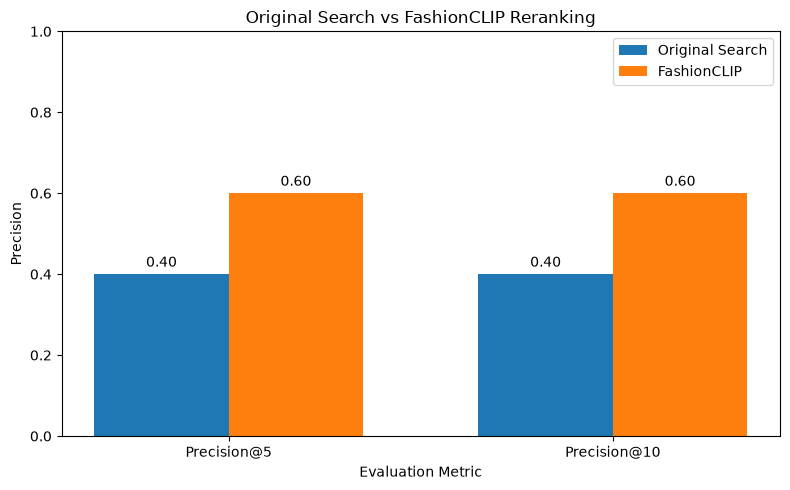

In [89]:
import matplotlib.pyplot as plt
import numpy as np

k_values = [5, 10]

original_precision = [
    precision_at_k(original_ranking, k)
    for k in k_values
]

fashionclip_precision = [
    precision_at_k(fashionclip_ranking, k)
    for k in k_values
]

x = np.arange(len(k_values))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(
    x - width / 2,
    original_precision,
    width,
    label="Original Search"
)

bars2 = ax.bar(
    x + width / 2,
    fashionclip_precision,
    width,
    label="FashionCLIP"
)

ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Precision")
ax.set_title("Original Search vs FashionCLIP Reranking")
ax.set_xticks(x)
ax.set_xticklabels(["Precision@5", "Precision@10"])
ax.set_ylim(0, 1)
ax.legend()

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

In [90]:
import numpy as np

def dcg_at_k(labels, k):

    labels = np.asarray(labels[:k])

    gains = 2**labels - 1
    discounts = np.log2(np.arange(2, len(labels) + 2))

    return np.sum(gains / discounts)


def ndcg_at_k(ranking, all_records, k):

    ranked_labels = [
        record["final_relevance"]
        for record in ranking[:k]
    ]

    all_labels = [
        record["final_relevance"]
        for record in all_records
    ]

    ideal_labels = sorted(all_labels, reverse=True)

    dcg = dcg_at_k(ranked_labels, k)
    idcg = dcg_at_k(ideal_labels, k)

    return dcg / idcg if idcg > 0 else 0.0

In [91]:
# For NDCG@5 and NDCG@10 -- Tells us from the relevant images appear in the Top-k, whether the most relevant images appear earlier.
for k in [5, 10]:

    original_ndcg = ndcg_at_k(
        original_ranking,
        evaluation_records,
        k
    )

    fashionclip_ndcg = ndcg_at_k(
        fashionclip_ranking,
        evaluation_records,
        k
    )

    print(f"NDCG@{k}")
    print(f"Original Search: {original_ndcg:.4f}")
    print(f"FashionCLIP: {fashionclip_ndcg:.4f}")
    print()

NDCG@5
Original Search: 0.6012
FashionCLIP: 0.6864

NDCG@10
Original Search: 0.6029
FashionCLIP: 0.7091



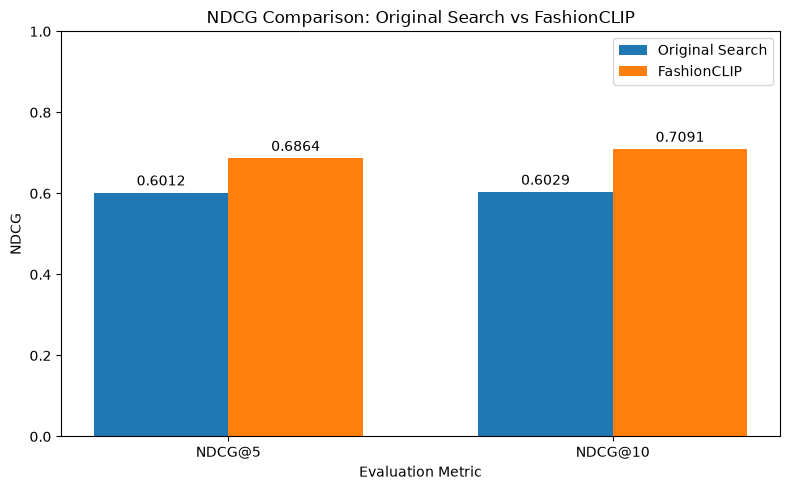

In [92]:
# NDCG Plot
import matplotlib.pyplot as plt
import numpy as np

k_values = [5, 10]

original_ndcg = [
    ndcg_at_k(original_ranking, evaluation_records, k)
    for k in k_values
]

fashionclip_ndcg = [
    ndcg_at_k(fashionclip_ranking, evaluation_records, k)
    for k in k_values
]

x = np.arange(len(k_values))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(
    x - width / 2,
    original_ndcg,
    width,
    label="Original Search"
)

bars2 = ax.bar(
    x + width / 2,
    fashionclip_ndcg,
    width,
    label="FashionCLIP"
)

ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("NDCG")
ax.set_title("NDCG Comparison: Original Search vs FashionCLIP")
ax.set_xticks(x)
ax.set_xticklabels(["NDCG@5", "NDCG@10"])
ax.set_ylim(0, 1)
ax.legend()

ax.bar_label(bars1, fmt="%.4f", padding=3)
ax.bar_label(bars2, fmt="%.4f", padding=3)

plt.tight_layout()
plt.show()

In [94]:
# Findings -
# We evaluated FashionCLIP reranking against the original aggregated image-search order using 19 unique fashion-reference images. 
# Based on human-reviewed relevance ratings, FashionCLIP improved Precision@5 and Precision@10 from 0.40 to 0.60. 
# It also improved NDCG@5 from 0.6012 to 0.6864 and NDCG@10 from 0.6029 to 0.7091. 
# These preliminary results suggest that FashionCLIP improves both the proportion of highly relevant images in the Top-K and their ordering.

In [ ]:
# Optional Gemini Label Analysis - Precision and NDCG (Later)

In [95]:
# Query diversity and retrieval diagnostics

# Calculate unique image contribution per query

from collections import defaultdict

query_stats = defaultdict(
    lambda: {
        "retrieved": 0,
        "new_unique": 0
    }
)

seen_ids = set()

for record in all_retrieved_images:

    query_number = record["query_number"]
    image_id = record["image_id"]

    query_stats[query_number]["retrieved"] += 1

    if image_id not in seen_ids:
        seen_ids.add(image_id)
        query_stats[query_number]["new_unique"] += 1

In [96]:
# Keeps track of image we have encountered
seen_ids = set()

In [97]:
# Create a query statistics table
import pandas as pd

query_df = pd.DataFrame([
    {
        "Query Number": query_number,
        "Retrieved": stats["retrieved"],
        "New Unique": stats["new_unique"],
        "Repeated": (
            stats["retrieved"] - stats["new_unique"]
        )
    }
    for query_number, stats in sorted(query_stats.items())
])

display(query_df)

,Query Number,Retrieved,New Unique,Repeated
0,1,10,10,0
1,2,10,6,4
2,3,8,2,6
3,4,1,1,0
4,5,3,0,3
5,6,1,0,1
6,7,3,0,3
7,8,6,0,6
8,9,1,0,1


In [98]:
print("Total retrieved:", query_df["Retrieved"].sum())
print("Total unique:", query_df["New Unique"].sum())
print("Repeated records:", query_df["Repeated"].sum())

Total retrieved: 43
Total unique: 19
Repeated records: 24


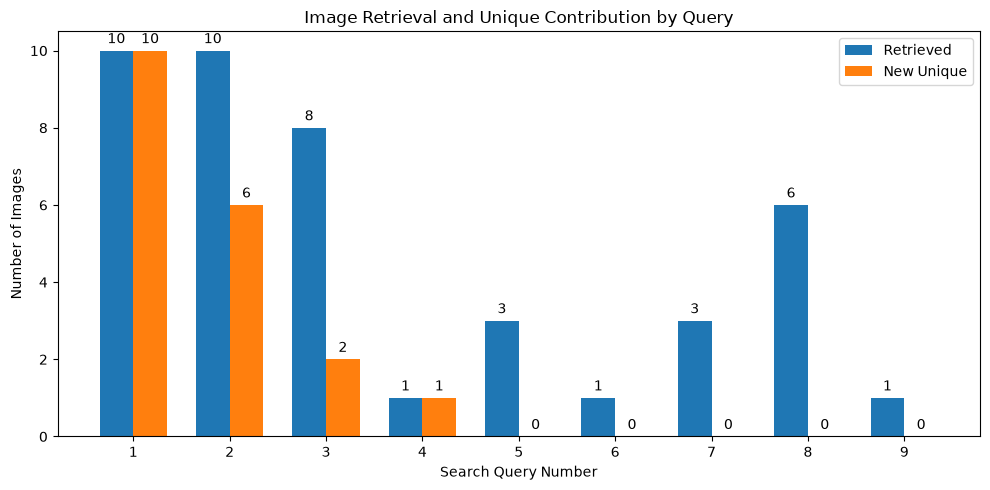

In [99]:
# Visualize Query Diversity
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(query_df))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

bars1 = ax.bar(
    x - width / 2,
    query_df["Retrieved"],
    width,
    label="Retrieved"
)

bars2 = ax.bar(
    x + width / 2,
    query_df["New Unique"],
    width,
    label="New Unique"
)

ax.set_xlabel("Search Query Number")
ax.set_ylabel("Number of Images")
ax.set_title("Image Retrieval and Unique Contribution by Query")

ax.set_xticks(x)
ax.set_xticklabels(query_df["Query Number"])

ax.legend()

ax.bar_label(bars1, padding=3)
ax.bar_label(bars2, padding=3)

plt.tight_layout()
plt.show()

In [100]:
# Calculate retrieval diagnostics

total_retrieved = len(all_retrieved_images)
total_unique = len(retrieved_images)

duplicate_count = total_retrieved - total_unique

duplicate_rate = duplicate_count / total_retrieved
unique_rate = total_unique / total_retrieved

print(f"Total Retrieved: {total_retrieved}")
print(f"Unique Images: {total_unique}")
print(f"Duplicate Records: {duplicate_count}")
print(f"Duplicate Rate: {duplicate_rate:.2%}")
print(f"Unique Yield: {unique_rate:.2%}")

Total Retrieved: 43
Unique Images: 19
Duplicate Records: 24
Duplicate Rate: 55.81%
Unique Yield: 44.19%


In [ ]:
# Candidate relevance rate - from human labelling
from collections import Counter

relevance_counts = Counter(
    record["final_relevance"]
    for record in evaluation_records
)

print("Highly relevant:", relevance_counts[2])
print("Partially relevant:", relevance_counts[1])
print("Irrelevant:", relevance_counts[0])

strict_relevance_rate = relevance_counts[2] / len(evaluation_records)

relaxed_relevance_rate = (
    relevance_counts[1] + relevance_counts[2]
) / len(evaluation_records)

print(f"Strict relevance rate: {strict_relevance_rate:.2%}")
print(f"Relaxed relevance rate: {relaxed_relevance_rate:.2%}")

Highly relevant: 9
Partially relevant: 7
Irrelevant: 3
Strict relevance rate: 47.37%
Relaxed relevance rate: 84.21%


In [102]:
# Final Evaluation Summary

summary_df = pd.DataFrame({
    "Metric": [
        "Precision@5",
        "Precision@10",
        "NDCG@5",
        "NDCG@10"
    ],
    "Original Search": [
        precision_at_k(original_ranking, 5),
        precision_at_k(original_ranking, 10),
        ndcg_at_k(original_ranking, evaluation_records, 5),
        ndcg_at_k(original_ranking, evaluation_records, 10)
    ],
    "FashionCLIP": [
        precision_at_k(fashionclip_ranking, 5),
        precision_at_k(fashionclip_ranking, 10),
        ndcg_at_k(fashionclip_ranking, evaluation_records, 5),
        ndcg_at_k(fashionclip_ranking, evaluation_records, 10)
    ]
})

summary_df["Absolute Improvement"] = (
    summary_df["FashionCLIP"] - summary_df["Original Search"]
)

display(summary_df.round(4))

,Metric,Original Search,FashionCLIP,Absolute Improvement
0,Precision@5,0.4000,0.6000,0.2000
1,Precision@10,0.4000,0.6000,0.2000
2,NDCG@5,0.6012,0.6864,0.0853
3,NDCG@10,0.6029,0.7091,0.1061


In [ ]:
# Phase 3 Integration Check
# Checks performed here - 
# 
import torch
# Load the Saved output
phase2_output = torch.load(
    "../outputs/phase_2_output.pt",
    map_location="cpu",
    weights_only=True
)

context_embedding = phase2_output["context_embedding"]
top_images = phase2_output["top_images"]
top_image_embeddings = phase2_output["top_image_embeddings"]

# Context embedding dimensions check
assert context_embedding.shape == (1, 512)
assert top_image_embeddings.shape == (len(top_images), 512)
assert len(top_images) == 10

# Context embedding L2 norm check
assert torch.allclose(
    context_embedding.norm(dim=-1),
    torch.ones(1),
    atol=1e-5
)

# Check all image embeddings are normalized
assert torch.allclose(
    top_image_embeddings.norm(dim=-1),
    torch.ones(len(top_images)),
    atol=1e-5
)

# Image ranking order check
assert all(
    image["rank"] == i
    for i, image in enumerate(top_images, start=1)
)

print("Student 3 interface validation passed.")

Student 3 interface validation passed.
